Exemplo 1 — Comparação de Arquiteturas de MLP (Multilayer Perceptron)
* Pergunta: Como a profundidade e a largura de uma rede MLP afetam o desempenho de classificação?
* Metodologia: Treinar no mesmo dataset Breast Cancer Wisconsin três arquiteturas:
MLP rasa (1 camada oculta, 16 neurônios), MLP média (2 camadas ocultas, 32 e 16 neurônios) e MLP
profunda (3 camadas ocultas, 64, 32 e 16 neurônios), mantendo fixos otimizador, taxa de aprendizado
e número de épocas. Avaliar com acurácia, F1-score e matriz de confusão, e discutir se a rede mais
complexa realmente supera a mais simples ou se há overfitting.
* Métricas centrais: acurácia, F1-score, matriz de confusão.

A lógica de pré-processamento:
1. Separação dos atributos (X) e do alvo (y).
2. Divisão entre treinamento e teste (80% / 20%).
3. Padronização dos atributos com StandardScaler, ajustando o scaler somente nos dados de treinamento.

* Separação de X e Y: X contém os 30 atributos que a rede neural utilizará para aprender e Y contém a resposta que a rede deverá aprender a prever (benigno ou maligno).
* Stratify: Tenta preservar a proporção tanto no treinamento quanto no teste.
* StandardScaler: Técnica de padronização que coloca os atributos em uma escala comparável.


In [2]:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Carregar os dados
from pathlib import Path

project_root = next(
    (path for path in [Path.cwd(), *Path.cwd().parents] if (path / "data" / "wdbc.xlsx").exists()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Nao foi possivel localizar data/wdbc.xlsx")

df = pd.read_excel(project_root / "data" / "wdbc.xlsx")

# 2. Separar atributos (X) e rótulos (y)
X = df.drop(columns=["ID", "Diagnosis"])

# M = Maligno (1)
# B = Benigno (0)
y = df["Diagnosis"].map({"M": 1, "B": 0})

# 3. Verificar os dados
print("Dimensões de X:", X.shape)
print("Dimensões de y:", y.shape)
print("\nDistribuição das classes:")
print(y.value_counts())

print("\nValores ausentes em X:", X.isna().sum().sum())
print("Valores ausentes em y:", y.isna().sum())

# 4. Dividir treino e teste
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 5. Padronizar os atributos
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 6. Conferir o resultado
print("\nTreinamento:", X_train_scaled.shape)
print("Teste:", X_test_scaled.shape)

print("\nPré-processamento concluído!")


Dimensões de X: (569, 30)
Dimensões de y: (569,)

Distribuição das classes:
Diagnosis
0    357
1    212
Name: count, dtype: int64

Valores ausentes em X: 0
Valores ausentes em y: 0

Treinamento: (455, 30)
Teste: (114, 30)

Pré-processamento concluído!


* fit_transform: calcula os parâmetros de padronização no treinamento e transforma os dados.
* transform: utiliza os mesmos parâmetros para transformar o teste (evita data leakage).

Pergunta central da pesquisa! 
* Como a quantidade de camadas ocultas e neurônios influencia o desempenho de uma rede neural MLP na classificação de tumores mamários?


MLP_Simples treinado!
Arquitetura: (16,)
Iterações: 334
Perda final: 0.0422

MLP_Intermediaria treinado!
Arquitetura: (32, 16)
Iterações: 267
Perda final: 0.0076

MLP_Profunda treinado!
Arquitetura: (64, 32, 16)
Iterações: 177
Perda final: 0.0015


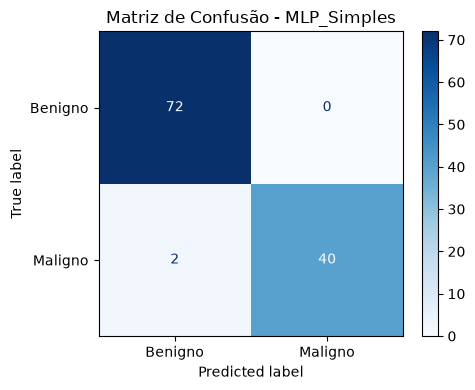

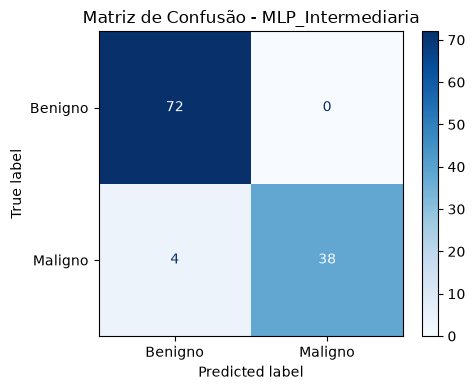

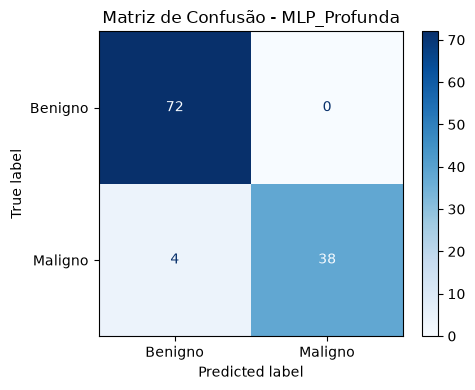

In [7]:
from sklearn.neural_network import MLPClassifier

# Definição dos 3 modelos com arquiteturas e hiperparâmetros distintos
modelos = {
    # Modelo 1: Uma camada oculta com 16 neurônios
    "MLP_Simples": MLPClassifier(
        hidden_layer_sizes=(16,),
        activation="relu",     # ativação não-linear(relu)
        solver="adam",
        alpha=0.0001,
        max_iter=1000,
        random_state=42
    ),

    # Modelo 2: Duas camadas ocultas com 32 e 16 neurônios
    "MLP_Intermediaria": MLPClassifier(
        hidden_layer_sizes=(32, 16),
        activation="relu",
        solver="adam",
        alpha=0.0001,
        max_iter=1000,
        random_state=42
    ),

    # Modelo 3: Três camadas ocultas com 64, 32, e 16 neurônios
    "MLP_Profunda": MLPClassifier(
        hidden_layer_sizes=(64, 32, 16),
        activation="relu",
        solver="adam",
        alpha=0.0001,
        max_iter=1000,
        random_state=42
    )
}

# Treinamento das três redes neurais
for nome, modelo in modelos.items():

    modelo.fit(X_train_scaled, y_train)

    print(f"\n{nome} treinado!")
    print(f"Arquitetura: {modelo.hidden_layer_sizes}")
    print(f"Iterações: {modelo.n_iter_}")
    print(f"Perda final: {modelo.loss_:.4f}")

# Matrizes de confusão (uma imagem por modelo)
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

for nome, modelo in modelos.items():
    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay.from_estimator(
        modelo,
        X_test_scaled,
        y_test,
        labels=[0, 1],
        display_labels=["Benigno", "Maligno"],
        cmap="Blues",
        ax=ax
    )
    ax.set_title(f"Matriz de Confusão - {nome}")
    plt.tight_layout()
    plt.savefig(f"matriz_confusao_{nome}.png", dpi=300, bbox_inches="tight")
    plt.show()

1. A MLP Simples apresentou a maior perda de treinamento.
2. A MLP Intermediária apresentou uma redução considerável.
3. A MLP Profunda apresentou a menor perda de treinamento.

Métricas, o que avalia?
* Acurácia: É a porcentagem geral de acertos do modelo (todos os acertos divididos pelo total de previsões).
* Precisão: De tudo o que o modelo classificou como "Sim", quanto realmente era "Sim". Foca em evitar Falsos Positivos (alarmes falsos).
* Recall: O que realmente era "Sim" no mundo real, quanto o modelo conseguiu capturar. Foca em evitar Falsos Negativos (deixar passar).
* F1-Score: Média harmônica entre a Precisão (Precision) e a Revocação (Recall), variando de 0 (pior) a 1 (melhor).
* Matriz de Confusão: Tabela que mostra a contagem exata de acertos e erros do modelo, cruzando o valor real com o valor previsto. Ela divide os resultados em 4 categorias: VP, VN, FP, FN.
* Área sob a Curva ROC: Mede a capacidade geral do modelo de distinguir entre as classes em diferentes limiares de decisão (thresholds), variando de 0.5 a 1.0.

In [5]:
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score
)

resultados = []

for nome, modelo in modelos.items():

    # 1. Previsões no conjunto de teste
    y_pred = modelo.predict(X_test_scaled)

    # 2. Probabilidades de classificação
    indice_maligno = list(modelo.classes_).index(1)
    y_prob = modelo.predict_proba(X_test_scaled)[:, indice_maligno]

    # 3. Cálculo das métricas
    acc = accuracy_score(y_test, y_pred)
    
    prec = precision_score(
        y_test, y_pred, pos_label=1, zero_division=0
    )

    rec = recall_score(
        y_test, y_pred, pos_label=1, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, pos_label=1, zero_division=0
    )

    auc = roc_auc_score(y_test, y_prob)

    # 4. Armazenamento dos resultados
    resultados.append({
        "Modelo": nome,
        "Arquitetura": str(modelo.hidden_layer_sizes),
        "Acurácia": round(acc, 4),
        "Precisão": round(prec, 4),
        "Recall": round(rec, 4),
        "F1-score": round(f1, 4),
        "ROC-AUC": round(auc, 4)
    })

    # 5. Matriz de confusão
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    print(f"\n--- {nome} ---")
    print("Matriz de Confusão:")
    print(cm)

# 6. Tabela comparativa
df_resultados = pd.DataFrame(resultados)

print("\n=== RESULTADOS COMPARATIVOS ===")
print(df_resultados.to_string(index=False))


--- MLP_Simples ---
Matriz de Confusão:
[[72  0]
 [ 2 40]]

--- MLP_Intermediaria ---
Matriz de Confusão:
[[72  0]
 [ 4 38]]

--- MLP_Profunda ---
Matriz de Confusão:
[[72  0]
 [ 4 38]]

=== RESULTADOS COMPARATIVOS ===
           Modelo  Arquitetura  Acurácia  Precisão  Recall  F1-score  ROC-AUC
      MLP_Simples        (16,)    0.9825       1.0  0.9524    0.9756   0.9970
MLP_Intermediaria     (32, 16)    0.9649       1.0  0.9048    0.9500   0.9937
     MLP_Profunda (64, 32, 16)    0.9649       1.0  0.9048    0.9500   0.9931


A MLP Simples apresentou o melhor resultado em quatro das cinco métricas, superando as duas arquiteturas mais profundas. A precisão ficou empatada entre os três modelos.

Com os resultados obtidos, podemos formular a seguinte interpretação:
- O aumento da quantidade de camadas ocultas não proporcionou melhoria no desempenho.
- A arquitetura mais simples apresentou os melhores resultados em acurácia, recall, F1-score e ROC-AUC.
- As arquiteturas intermediária e profunda apresentaram resultados iguais em acurácia, precisão, recall e F1-score.
- A maior complexidade da rede não garantiu maior capacidade de generalização.
- Mas atenção: não podemos afirmar definitivamente que redes simples são melhores para esse problema. Fizemos uma única divisão de treino e teste. Para uma conclusão mais robusta, seria interessante repetir a avaliação com validação cruzada estratificada.

Por que a MLP com apenas uma camada oculta superou as outras duas?
- Porque bases de dados tabulares médicas costumam ser pequenas e ter relações relativamente diretas, fazendo com que redes complexas sofram com excesso de parâmetros.

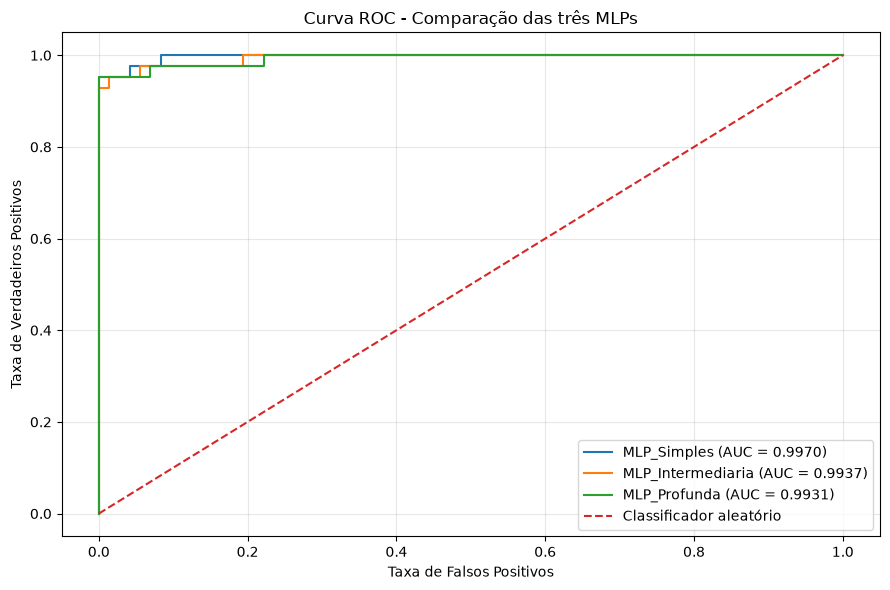

In [6]:
import matplotlib.pyplot as plt 
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(9, 6))

for nome, modelo in modelos.items():

    # Probabilidade da classe positiva (Maligno = 1)
    indice_maligno = list(modelo.classes_).index(1)
    y_prob = modelo.predict_proba(X_test_scaled)[:, indice_maligno]

    # Calcular curva ROC
    fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    valor_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{nome} (AUC = {valor_auc:.4f})"
    )

# Linha de referência
plt.plot([0, 1], [0, 1], linestyle="--", label="Classificador aleatório")

plt.xlabel("Taxa de Falsos Positivos")
plt.ylabel("Taxa de Verdadeiros Positivos")
plt.title("Curva ROC - Comparação das três MLPs")

plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("curva_roc.png", dpi=300, bbox_inches="tight")
plt.show()

In [8]:
for nome, modelo in modelos.items():

    acc_treino = modelo.score(X_train_scaled, y_train)
    acc_teste = modelo.score(X_test_scaled, y_test)

    print(f"\n{nome}")
    print(f"Acurácia treino: {acc_treino:.4f}")
    print(f"Acurácia teste: {acc_teste:.4f}")
    print(f"Diferença: {acc_treino - acc_teste:.4f}")


MLP_Simples
Acurácia treino: 0.9912
Acurácia teste: 0.9825
Diferença: 0.0088

MLP_Intermediaria
Acurácia treino: 1.0000
Acurácia teste: 0.9649
Diferença: 0.0351

MLP_Profunda
Acurácia treino: 1.0000
Acurácia teste: 0.9649
Diferença: 0.0351
